**Source package:** generated datasets and trained checkpoints are not included. Generate `datasets/highway.npz` before Run All. This notebook then trains a new model from random initialization. Follow the [build-from-source guide](../docs/FROM_SOURCE.md) before Run All. Saved outputs are cleared except the static teaching figures.

# Lab 1: Learn a World Model from Experience

**Can a neural network learn what will happen after an action?**

In [ ]:
# Locate the complete lab and import its bundled source package.
import os
import sys
from pathlib import Path

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file()
     and (p / "src/lab1/__init__.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Open the complete lab folder containing pyproject.toml and src/lab1. "
        "Follow START_HERE.md to launch Jupyter from that folder."
    )
os.chdir(project_root)
sys.path.insert(0, str(project_root / "src"))
print("working dir:", Path.cwd())
print("kernel Python:", sys.executable)

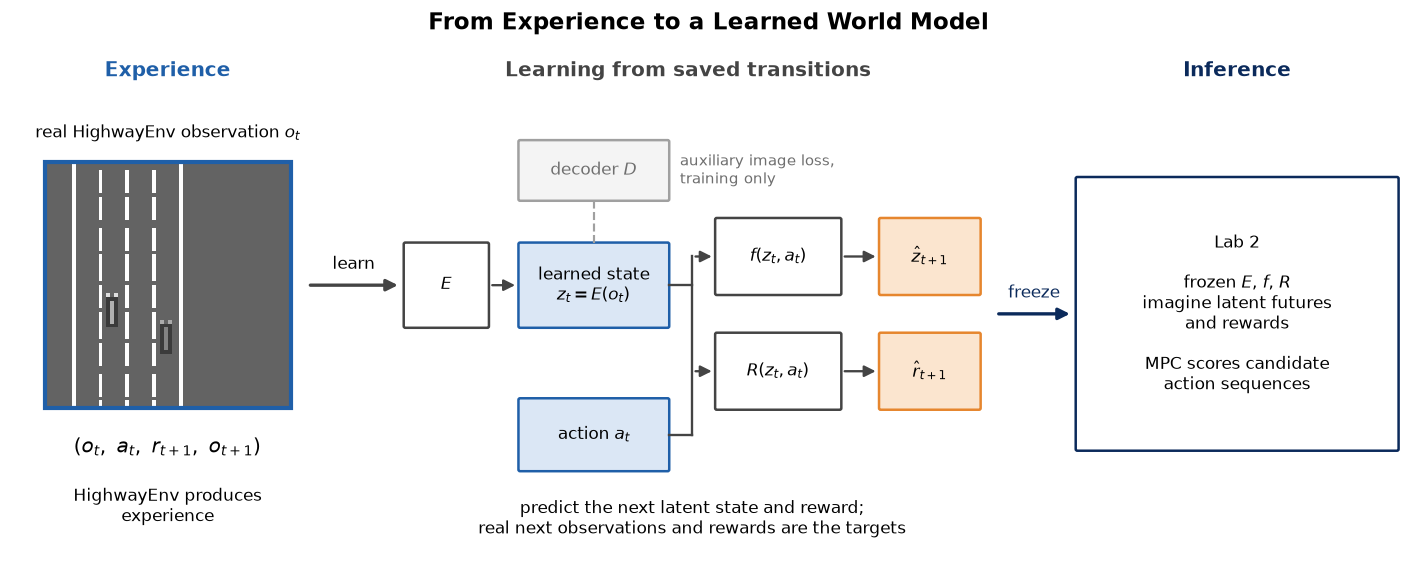

In [ ]:
from pathlib import Path
from lab1.data import load_episodes
from lab1.visualization import plot_experience_to_world_model
from notebooks.local_workflow import require_student_file
from notebooks.upright_view import upright

DATASET_PATH = Path("datasets/highway.npz")
require_student_file(
    DATASET_PATH,
    "Saved experience was not found. From the extracted package folder, run: "
    "uv run python scripts/collect.py --config configs/lab.yaml",
)
opening = load_episodes(DATASET_PATH)[0].obs[4, -1]
_ = plot_experience_to_world_model(upright(opening))

In Lab 1, you train a world model from saved HighwayEnv experience.
In Lab 2, you freeze that model and use its predictions for imagination and MPC.

## One Saved Transition

Training uses 20,000 saved transitions $(o_t, a_t, r_{t+1}, o_{t+1})$, collected
once before training while a random policy drove. Here is one. The observation
$o_t$ is four stacked grayscale frames. The saved action came from the random
data-collection policy, not from a planner. HighwayEnv then produced the reward
and the next observation. The model receives $o_t$ and $a_t$; the real
$r_{t+1}$ and $o_{t+1}$ are the targets its predictions are checked against.

In [ ]:
from lab1.config import Config
from lab1.visualization import plot_saved_transition
from notebooks.upright_view import upright_figure

cfg = Config.load("configs/lab.yaml")
cfg.data.dataset_path = str(DATASET_PATH)
episodes = load_episodes(DATASET_PATH)
TRAINING_TRANSITIONS = sum(len(ep) for ep in episodes)
cfg.data.num_transitions = TRAINING_TRANSITIONS
print(f"{TRAINING_TRANSITIONS:,} saved transitions in {len(episodes)} trajectories")
EXAMPLE_STEP = 6
EXAMPLE_EPISODE = (
    3 if len(episodes) > 3 and len(episodes[3]) > EXAMPLE_STEP
    else next(i for i, episode in enumerate(episodes) if len(episode) > EXAMPLE_STEP)
)
print(f"Example: trajectory {EXAMPLE_EPISODE}, step {EXAMPLE_STEP}")
upright_figure(plot_saved_transition(episodes[EXAMPLE_EPISODE], t=EXAMPLE_STEP));

**Prompt 1.** In the transition above, which quantities does the model receive
as input, and which two quantities supervise its predictions?

## Configure Your Training

Choose any positive integer number of epochs below. Twenty is the default
teaching run; 5 is quicker and 40 is longer. These are examples, not restrictions.
The dataset and architecture stay unchanged. Run All creates a new attempt
folder and preserves earlier results. Training time is measured when you run.

In [ ]:
EPOCHS = 20


In [ ]:
from notebooks.local_workflow import new_training_attempt

if type(EPOCHS) is not int or EPOCHS <= 0:
    raise ValueError("EPOCHS must be a positive integer, for example 3 or 5.")
cfg.training.epochs = EPOCHS
RUN_NAME = "quick_run_01"
MY_BUILD_ROOT = Path("outputs/my_build")
MY_BUILD_DIR = MY_BUILD_ROOT / RUN_NAME
TRAINING_DIR = new_training_attempt(MY_BUILD_DIR)


## What the World Model Learns

The encoder $E$ produces the learned state $z_t = E(o_t)$, 64 numbers. From
$z_t$ and $a_t$, the dynamics head predicts the next latent,
$\hat z_{t+1} = f(z_t, a_t)$, and the reward head predicts the environment
reward, $\hat r_{t+1} = R(z_t, a_t)$. The targets come from real experience:
the encoded next observation $z_{t+1} = E(o_{t+1})$ and the received reward
$r_{t+1}$. The model predicts in its own learned state, not the true
environment state.

In [ ]:
from lab1.visualization import plot_learning_diagram

plot_learning_diagram();

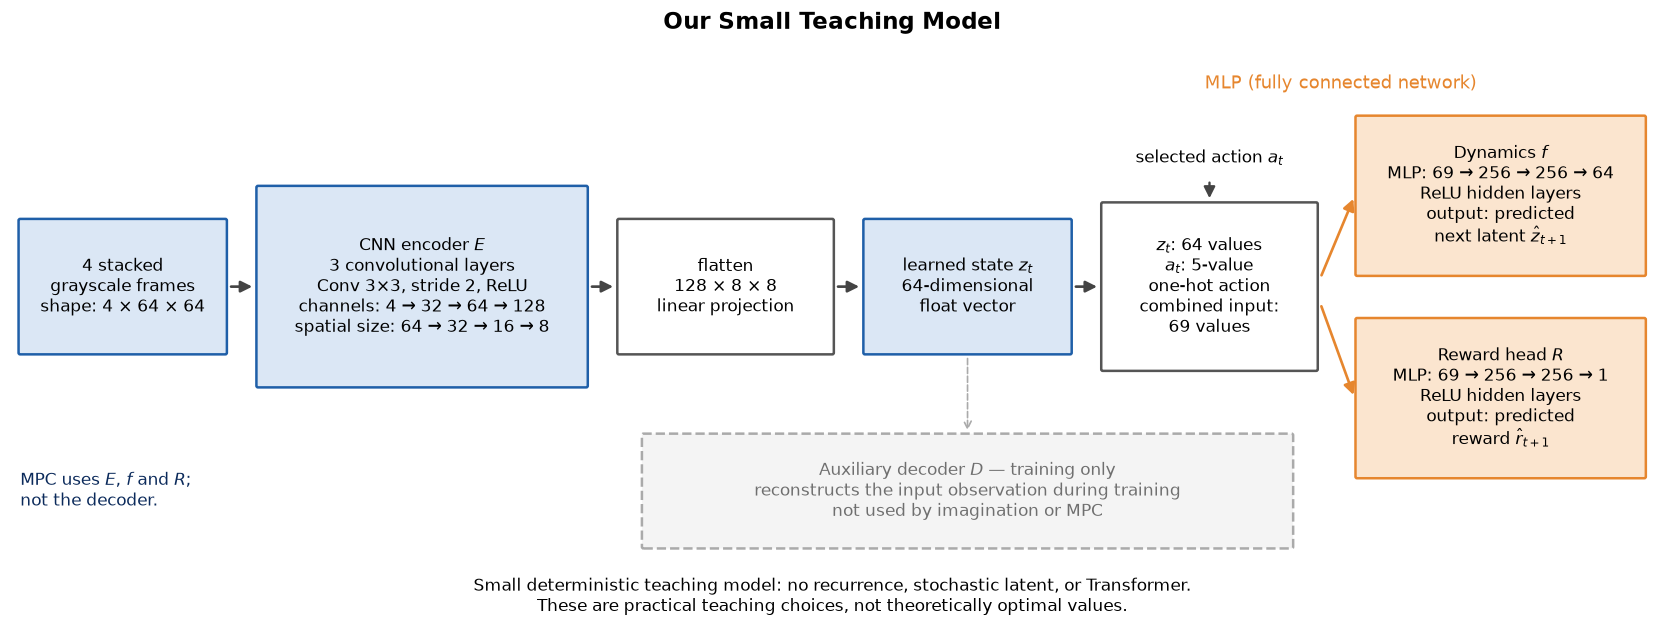

In [ ]:
import torch

from lab1.data import load_num_actions
from lab1.models import WorldModel
from notebooks.teaching_architecture import plot_teaching_architecture

# Inspect a model without changing the random state used by the training demo.
with torch.random.fork_rng():
    architecture_model = WorldModel.from_config(
        cfg.model, cfg.env, load_num_actions(cfg.data.dataset_path)
    )
_ = plot_teaching_architecture(architecture_model, cfg.env.image_size)
del architecture_model

The CNN extracts spatial information from four recent frames; the 64-dimensional
learned state compresses it into 64 floating-point values. The two MLP heads
combine that state with the selected action to predict the next latent and
reward. The decoder supports representation learning during training but is not
used for planning. Three convolutional layers and widths 64 and 256 are practical
teaching choices, not universal world-model requirements.

<details>
<summary>Model and training settings</summary>

**Architecture** — parameter counts verified from the instantiated model:

| Component | Parameters |
|---|---:|
| Encoder | 617,888 |
| Dynamics | 100,160 |
| Reward head | 83,969 |
| Auxiliary decoder | 698,468 |
| Total | 1,500,485 |
| Encoder + dynamics + reward path used for planning | 802,017 |

**Student model (default 20 epochs):** 20,000 saved transitions; 90/10 split by complete
trajectory; `EPOCHS` passes (default 20); batch size 64; Adam; learning rate $3\times10^{-4}$;
gradient clipping 1.0; next-latent, reward and auxiliary-image loss weights
all 1.0; seed 0.

**Lab 2:** uses the model exported by this notebook. The world model is frozen
while MPC searches for actions. These teaching settings were not exhaustively optimized.

</details>

The components are trained jointly on fixed simulator transitions. No actor,
critic, policy or planner is trained here. The dataset also records when an
episode ends, but this model has no head that predicts it.

## One Parameter Update

**Predict → Calculate loss → Backpropagate → Update parameters**

The loss adds three prediction errors, with equal weights in this lab:

$$
\mathcal{L}_{\mathrm{train}}
= \mathcal{L}_{\mathrm{next\ latent}}
+ \mathcal{L}_{\mathrm{reward}}
+ \mathcal{L}_{\mathrm{aux\ image}}.
$$

These compare the next latent with the encoded real next observation, the
predicted reward with the received reward, and the reconstructed current image
with the real current image. The next cell performs one real update on 64 saved
transitions and prints the loss before and after.

<details>
<summary>Technical detail: one update (pseudocode)</summary>

```python
predictions = model(obs, action)
loss = next_latent_error + reward_error + reconstruction_error
optimizer.zero_grad()
loss.backward()
optimizer.step()
```

The real demonstration uses `WorldModel.compute_losses`, including a fixed
encoded next-observation target and gradient clipping, just like the trainer.
Expand its code to inspect the implementation.

</details>

In [ ]:
import copy

import torch

from lab1.data import load_num_actions, make_dataloaders
from lab1.models import WorldModel
from lab1.utils.seed import set_seed

set_seed(cfg.seed)
train_loader, val_loader, train_eps, val_eps = make_dataloaders(cfg)
num_actions = load_num_actions(cfg.data.dataset_path)
weights = {
    "dynamics_weight": cfg.training.dynamics_loss_weight,
    "reward_weight": cfg.training.reward_loss_weight,
    "recon_weight": cfg.training.recon_loss_weight,
}

demo = WorldModel.from_config(cfg.model, cfg.env, num_actions)  # random weights
optimizer = torch.optim.Adam(demo.parameters(), lr=cfg.training.learning_rate)
batch = next(iter(train_loader))
start_weights = copy.deepcopy(demo.state_dict())

loss = demo.compute_losses(batch, **weights)["total"]
optimizer.zero_grad()
loss.backward()
torch.nn.utils.clip_grad_norm_(demo.parameters(), cfg.training.grad_clip)
optimizer.step()

with torch.no_grad():
    new_loss = demo.compute_losses(batch, **weights)["total"]
changed = sum(not torch.equal(start_weights[k], v) for k, v in demo.state_dict().items())
print(f"combined loss on this minibatch: {loss.item():.4f} before, "
      f"{new_loss.item():.4f} after one update")
print(f"parameter tensors changed: {changed} of {len(start_weights)}")

One update changes the model parameters to reduce the combined prediction loss
on this minibatch.

## Train the World Model

One epoch is one pass over the training trajectories. Your chosen `EPOCHS`
sets the training budget; the CNN/MLP architecture and minibatches of 64 stay
the same. Validation uses complete held-out trajectories. The next cell trains
from random weights and keeps the best-validation checkpoint.

In [ ]:
import contextlib
import io
import time

from lab1.training import Trainer, resolve_device
from lab1.utils.checkpoint import load_checkpoint

set_seed(cfg.seed)
train_loader, val_loader, train_eps, val_eps = make_dataloaders(cfg)
model = WorldModel.from_config(cfg.model, cfg.env, num_actions)
before = copy.deepcopy(model)
print(f"{len(train_eps)} training and {len(val_eps)} held-out trajectories, "
      f"{len(train_loader)} minibatches per epoch")

if any(TRAINING_DIR.iterdir()):
    TRAINING_DIR = new_training_attempt(MY_BUILD_DIR)

cfg.training.checkpoint_dir = str(TRAINING_DIR / "checkpoints")
cfg.training.log_dir = str(TRAINING_DIR / "runs")
device = resolve_device(cfg.training.device)
trainer = Trainer(cfg, model, train_loader, val_loader, device)
training_started = time.perf_counter()
with contextlib.redirect_stderr(io.StringIO()):
    best_checkpoint = trainer.fit()

print(f"Measured training time ({EPOCHS} epochs): {time.perf_counter() - training_started:.1f} s")

after = WorldModel.from_config(cfg.model, cfg.env, num_actions)
saved = load_checkpoint(best_checkpoint, after)
changed = sum(
    not torch.equal(p, q)
    for p, q in zip(before.state_dict().values(), after.state_dict().values())
)
print(f"Best validation loss at epoch {saved['epoch']}")
print(f"parameter tensors that differ from the random start: "
      f"{changed} of {len(after.state_dict())}")

Training and validation loss for the three terms, epoch by epoch, on a log
scale. The first training point averages over the whole first epoch, when the
weights change fastest.

In [ ]:
import json

from lab1.visualization import plot_losses

history = json.loads((best_checkpoint.parent / "history.json").read_text())
plot_losses(history, log_scale=True, include_total=False);

## Did the Predictions Improve?

Falling loss is only part of the evidence. The real question is whether the
model's predictions improved. Here the random starting model and the trained
model are compared on the same held-out transitions.

**Next-latent prediction.** We measure the one-step error between
$\hat z_{t+1}$ and $z_{t+1} = E(o_{t+1})$. Each model has its own encoder, so
raw errors live on different scales: a random encoder maps almost every
observation to nearly the same latent, which makes even a poor prediction look
small. We therefore divide the mean squared error by the variance of the target
latents. A value of 1 means no better than always predicting the average latent.

In [ ]:
from lab1.visualization import plot_latent_before_after, prediction_metrics

start = prediction_metrics(before, val_eps)
trained = prediction_metrics(after, val_eps)
for name, m in [("random start", start), ("trained", trained)]:
    print(f"{name:13s} one-step latent MSE {m['latent_mse']:.5f}  "
          f"normalized error {m['latent_error']:.3f}")
plot_latent_before_after(start, trained);

**Reward prediction.** Each dot is one held-out transition. Red crosses mark
rewards below 0.3, not verified safety labels. Compare random initialization
with your trained model; low-reward prediction matters when MPC ranks actions.

**Prompt 2.** Why can poor prediction of low rewards mislead a planner?

In [ ]:
from lab1.visualization import plot_reward_before_after

panels = [("random start", start), (f"after {EPOCHS} epochs", trained)]
for name, m in panels:
    low = m["reward"] < 0.3
    print(f"{name:16s} mean abs. error {m['reward_mae']:.3f} | mean prediction: "
          f"reward < 0.3 {m['reward_pred'][low].mean():.2f}, "
          f"others {m['reward_pred'][~low].mean():.2f}")
plot_reward_before_after(panels);

### Inspect Auxiliary Reconstructions

The top row is real held-out experience; the bottom row is the decoder's
reconstruction of those same current observations. This is not a future
prediction. Pixel quality and next-latent prediction error measure different
things; MPC does not use the decoder.


In [ ]:
from lab1.visualization import plot_reconstruction
from notebooks.upright_view import upright_figure

held_out_observations = next(iter(val_loader))['obs']
_ = upright_figure(plot_reconstruction(after, held_out_observations, n=4))


Compare the before/after measurements from your own run. Twenty epochs are the
default teaching run, not a guarantee of accurate prediction or good
control. A separate three-seed experiment found improvements on average from
20 to 40 epochs; that does not mean every additional epoch always helps.

## From Learning to Imagination

Training has ended. Lab 2 freezes this kind of model: nothing is learned
while it plans. It encodes the current observation once, then the dynamics and
reward heads predict recursively, each predicted latent becoming the next
input. These imagined futures and rewards are what MPC uses.

In [ ]:
from lab1.visualization import plot_learning_to_imagination

plot_learning_to_imagination();

Your model predicts latent states and rewards without decoding images.
Lab 2 can load your saved model and use the same MPC algorithm to act.

**Prompt 3.** Why do imagination and MPC not need decoded images?

<details>
<summary><b>Technical note:</b> why the prediction target is held fixed</summary>

In code the target is `encoder(next_obs).detach()`, so the encoded next
observation is treated as fixed within an update. Gradients still train the
prediction branch: the dynamics head and, through $z_t$, the encoder. Holding
the target fixed does not by itself prevent a constant latent representation,
which would make the next-latent loss trivially small. The reward and auxiliary
image losses help anchor the representation.

</details>

## Save Your World Model for Lab 2

The model-only handoff contains weights, architecture, preprocessing and training metadata, not optimizer state. Lab 2 finds the most recently exported Lab 1 checkpoint and uses it for imagination and MPC.


In [ ]:
from notebooks.local_workflow import save_student_model


def export_world_model(model, cfg, transitions, selected_epoch, run_directory):
    destination = run_directory / "my_lab1_world_model.pt"
    save_student_model(
        destination, model, cfg, transitions, selected_epoch=selected_epoch
    )
    print("Lab 1 complete.\nYour world model was saved to:")
    print(destination.as_posix())
    print("\nNext: Open notebooks/2_imagine_and_plan.ipynb")
    print("Lab 2 finds this checkpoint automatically.")
    try:
        from google.colab import files
    except ImportError:
        pass
    else:
        files.download(str(destination))
    return destination


In [ ]:
personal_model_path = export_world_model(
    after, cfg, TRAINING_TRANSITIONS, saved["epoch"], TRAINING_DIR
)
